<div style="background: linear-gradient(135deg, #16324f 0%, #2b5c8f 100%); color: #ffffff; padding: 28px 32px; border-radius: 10px; margin-bottom: 18px; box-shadow: 0 4px 12px rgba(0,0,0,0.08);">
  <div style="font-size: 12px; text-transform: uppercase; letter-spacing: 1.4px; opacity: 0.85; margin-bottom: 6px;">
    Projet Python pour la Data Science • Analyse comparative internationale (2019)
  </div>
  <h1 style="margin: 0 0 10px 0; font-size: 26px; font-weight: 700; line-height: 1.25; color: #ffffff;">
    Déchets plastiques mal gérés et mortalité infantile dans le monde
  </h1>
  <p style="margin: 0 0 14px 0; font-size: 14.5px; opacity: 0.92; line-height: 1.5;">
    Exploration statistique de l'association entre mauvaise gestion des déchets plastiques, santé infantile, niveau de richesse économique (PIB/hab.) et infrastructures d'assainissement.
  </p>
  <div style="display: inline-block; background: rgba(255,255,255,0.14); padding: 6px 14px; border-radius: 20px; font-size: 13px;">
    <strong>Auteurs :</strong> Rayan GOMA • Marius PRIBETICH • Anton LUCIBELLO
  </div>
</div>

<div style="background-color: #f0f5fa; border-left: 5px solid #2b5c8f; padding: 16px 20px; border-radius: 6px; margin-bottom: 14px;">
  <div style="font-weight: 700; color: #16324f; font-size: 15px; margin-bottom: 6px;">Problématique de recherche</div>
  <p style="margin: 0 0 8px 0; color: #1e293b; line-height: 1.55;">
    En <strong>2019</strong>, parmi les pays et territoires disposant de données comparables :
  </p>
  <ol style="margin: 0; padding-left: 20px; color: #1e293b; line-height: 1.6;">
    <li>Observe-t-on une <strong>association descriptive</strong> entre la quantité de déchets plastiques mal gérés par habitant et le taux de mortalité infantile ?</li>
    <li>Cette association demeure-t-elle similaire lorsqu'on compare séparément les pays selon leur niveau de <strong>PIB par habitant</strong> et leur taux d'<strong>accès à l'assainissement de base</strong> ?</li>
  </ol>
</div>

<div style="background-color: #fffbeb; border-left: 5px solid #d97706; padding: 14px 18px; border-radius: 6px; margin-bottom: 18px;">
  <div style="font-weight: 700; color: #92400e; font-size: 14px; margin-bottom: 4px;">Précaution d'interprétation (erreur écologique)</div>
  <p style="margin: 0; color: #78350f; font-size: 13.5px; line-height: 1.5;">
    Cette étude repose exclusivement sur des <strong>indicateurs agrégés à l'échelle nationale</strong>. Elle met en évidence des régularités statistiques entre pays, mais <strong>ne démontre aucun lien de causalité</strong> directe entre le plastique et les décès infantiles, et ne renseigne pas sur l'exposition individuelle des enfants.
  </p>
</div>

<div style="background-color: #f8fafc; border: 1px solid #e2e8f0; padding: 14px 20px; border-radius: 8px;">
  <div style="font-weight: 700; color: #334155; font-size: 14px; margin-bottom: 8px;">Sommaire du notebook</div>
  <ul style="margin: 0; padding-left: 18px; line-height: 1.7; font-size: 13.5px; columns: 2;">
    <li><a href="#sec-1" style="color: #2b5c8f; text-decoration: none;"><strong>1.</strong> Sources, variables et protocole</a></li>
    <li><a href="#sec-2" style="color: #2b5c8f; text-decoration: none;"><strong>2.</strong> Environnement et modules du projet</a></li>
    <li><a href="#sec-3" style="color: #2b5c8f; text-decoration: none;"><strong>3.</strong> Préparation des tables et audit de jointure</a></li>
    <li><a href="#sec-4" style="color: #2b5c8f; text-decoration: none;"><strong>4.</strong> Statistiques descriptives</a></li>
    <li><a href="#sec-5" style="color: #2b5c8f; text-decoration: none;"><strong>5.</strong> Graphique 1 — Distributions univariées</a></li>
    <li><a href="#sec-6" style="color: #2b5c8f; text-decoration: none;"><strong>6.</strong> Graphique 2 — Plastiques et mortalité infantile</a></li>
    <li><a href="#sec-7" style="color: #2b5c8f; text-decoration: none;"><strong>7.</strong> Graphique 3 — Comparaison par niveau de PIB</a></li>
    <li><a href="#sec-8" style="color: #2b5c8f; text-decoration: none;"><strong>8.</strong> Graphique 4 — Comparaison par assainissement</a></li>
    <li><a href="#sec-9" style="color: #2b5c8f; text-decoration: none;"><strong>9.</strong> Synthèse, limites et conclusion</a></li>
  </ul>
</div>

<a id="sec-1"></a>
## 1. Sources de données, dictionnaire des variables et méthode

L'analyse croise quatre indicateurs internationaux mesurés pour l'année de référence **2019**, sélectionnée car elle correspond à l'estimation mondiale de référence de Meijer et al. (2021) sur les déchets plastiques tout en évitant les perturbations statistiques liées à la pandémie de Covid-19 à partir de 2020.

| Variable dans le code | Indicateur étudié | Source & Code officiel | Unité de mesure | Limite d'interprétation |
| :--- | :--- | :--- | :--- | :--- |
| `plastic_kg_per_person` | **Déchets plastiques mal gérés** | Our World in Data — *Meijer et al. (2021)* | kg / habitant / an | Estime les déchets non recyclés, non incinérés ou mal confinés, sans mesurer l'exposition biologique directe. |
| `infant_mortality_per_1000` | **Taux de mortalité infantile** | Banque mondiale (WDI) — `SP.DYN.IMRT.IN` | Décès avant 1 an pour 1 000 naissances vivantes | Indicateur sanitaire global influencé par de nombreux facteurs (soins néonatals, nutrition, infections). |
| `gdp_pc_ppp_2019` | **PIB par habitant (PPA)** | Banque mondiale (WDI) — `NY.GDP.PCAP.PP.KD` | Dollars internationaux constants de 2021 (PPA) | Reflète le niveau moyen de développement économique, mais masque les inégalités internes. |
| `basic_sanitation_pct` | **Accès à l'assainissement de base** | Banque mondiale (WDI) — `SH.STA.BASS.ZS` | % de la population totale | Mesure l'accès aux installations sanitaires (eaux usées/excréta), et non la collecte des déchets solides. |

### Protocole de traitement des données
- **Filtrage géographique :** les agrégats supranationaux (continents, régions Banque mondiale) et les territoires absents du référentiel World Bank sont écartés afin d'éviter tout double comptage.
- **Appariement :** les quatre sources sont fusionnées par **code pays standardisé ISO3** et par **année (2019)**.
- **Gestion des valeurs manquantes :** aucune valeur manquante n'est imputée par zéro (ce qui fausserait artificiellement les distributions). L'association bivariée principale mobilise tous les pays renseignés pour le couple plastique/mortalité, tandis que les comparaisons stratifiées s'appuient sur les **cas complets** pour les quatre variables.
- **Stratégie descriptive :** le PIB par habitant et l'assainissement sont étudiés en tant que **variables de contexte** par stratification en sous-groupes, et non comme des contrôles causaux économétriques.

<a id="sec-2"></a>
## 2. Environnement et chargement des modules

Lancer Jupyter depuis la racine du dépôt permet à `Path.cwd()` de retrouver les fichiers `cleaning.py` et `download.py`. `sys.path` indique à Python où chercher ces scripts. Le notebook n’effectue aucun clonage GitHub, aucune recherche dans les dossiers personnels et ne lit aucun token. Les données doivent être téléchargées explicitement avec `python download.py` avant le lancement de **Run All**.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

# Ce notebook est prévu pour être lancé depuis la racine du dépôt.
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "cleaning.py").exists():
    raise FileNotFoundError(
        "Ouvrir Jupyter depuis la racine du dépôt, là où se trouvent cleaning.py et download.py."
    )

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from cleaning import prepare_project_data
from download import RAW_ROOT

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#fcfcfd",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#cbd5e1",
    "axes.labelcolor": "#1e293b",
    "axes.titleweight": "bold",
    "xtick.color": "#475569",
    "ytick.color": "#475569",
    "font.size": 10,
})

FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"
TABLES_DIR = PROJECT_DIR / "outputs" / "tables"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Racine du projet : {PROJECT_DIR}")
print(f"Dossier des données brutes : {RAW_ROOT}")


Racine du projet : C:\Users\cibel\Documents\GitHub\Python-pour-la-data-science
Dossier des données brutes : C:\Users\cibel\Documents\GitHub\Python-pour-la-data-science\data\raw


<a id="sec-3"></a>
## 3. Acquisition, appariement ISO3 et audit de qualité

Avant d’exécuter le notebook sur un nouveau clone, lancer `python download.py` depuis la racine du dépôt. Cette commande télécharge les sources absentes dans `data/raw/`; elle conserve les snapshots présents, sauf si l’on demande explicitement `--force`.

La fonction `prepare_project_data()` lit ensuite les fichiers locaux, filtre l’année 2019, retire les agrégats et relie les indicateurs par code ISO3 et année. Elle produit trois tables : `df_merged` (toutes les entités appariables), `df_pair` (déchets et mortalité présents) et `df_complete` (les quatre indicateurs présents).


In [2]:
# La collecte reste une étape explicite, séparée de l'analyse.
required_raw_files = [
    RAW_ROOT / "owid_mismanaged_plastic_per_capita.csv",
    RAW_ROOT / "wdi_countries.json",
    RAW_ROOT / "wdi_infant_mortality_2019.json",
    RAW_ROOT / "wdi_gdp_per_capita_ppp_2019.json",
    RAW_ROOT / "wdi_basic_sanitation_2019.json",
]

missing_files = [path.name for path in required_raw_files if not path.exists()]
if missing_files:
    missing_list = ", ".join(missing_files)
    raise FileNotFoundError(
        f"Données manquantes dans {RAW_ROOT}: {missing_list}. "
        "Lancer `python download.py` depuis la racine du dépôt, puis redémarrer Run All."
    )

tables = prepare_project_data()

df_merged = tables["merged"]
df_pair = tables["pair_plastic_infant"]
df_complete = tables["complete"]
df_excluded = tables["excluded"]
country_metadata = tables["country_metadata"]

print(f"• Entités appariables (OWID 2019)                 : {len(df_merged)}")
print(f"• Entités avec déchets + mortalité infantile      : {len(df_pair)}")
print(f"• Entités complètes pour les quatre indicateurs   : {len(df_complete)}")


• Entités appariables (OWID 2019)                 : 153
• Entités avec déchets + mortalité infantile      : 151
• Entités complètes pour les quatre indicateurs   : 139


### Bilan détaillé de la jointure et traçabilité des exclusions

Afin de garantir une transparence méthodologique totale, les tableaux ci-dessous documentent :
- **L'évolution des effectifs** à chaque filtre du pipeline.
- **La complétude par variable** (nombre de valeurs observées vs manquantes sur les 153 entités retenues).
- **Les bornes (minimum / maximum)** permettant de vérifier l'absence d'anomalies de codage.
- **La liste des entités écartées** lors de l'appariement avec le référentiel de la Banque mondiale.

In [3]:
# 1. Tableau d'audit des effectifs par étape
audit_df = pd.DataFrame([
    {"Étape du filtrage": "Entités OWID 2019 retenues (pays et territoires)", "Effectif (n)": len(df_merged)},
    {"Étape du filtrage": "Entités OWID 2019 exclues (agrégats régionaux / hors périmètre WDI)", "Effectif (n)": len(df_excluded)},
    {"Étape du filtrage": "Échantillon principal (déchets plastiques + mortalité infantile)", "Effectif (n)": len(df_pair)},
    {"Étape du filtrage": "Échantillon complet (les 4 variables renseignées)", "Effectif (n)": len(df_complete)},
])
display(Markdown("#### 1. Suivi des effectifs à chaque étape"))
display(audit_df)

# 2. Tableau de complétude et d'étendue des variables
cols_labels = {
    "plastic_kg_per_person": "Déchets plastiques mal gérés (kg/hab./an)",
    "infant_mortality_per_1000": "Mortalité infantile (pour 1 000 naissances)",
    "gdp_pc_ppp_2019": "PIB par habitant (PPA 2021)",
    "basic_sanitation_pct": "Assainissement de base (% population)",
}

quality_df = pd.DataFrame([
    {
        "Indicateur": label,
        "Présents": int(df_merged[col].notna().sum()),
        "Manquants": int(df_merged[col].isna().sum()),
        "Taux complétude (%)": round(df_merged[col].notna().mean() * 100, 1),
        "Minimum": round(df_merged[col].min(), 3),
        "Maximum": round(df_merged[col].max(), 2),
    }
    for col, label in cols_labels.items()
])
display(Markdown("#### 2. Complétude et valeurs extrêmes sur les 153 entités retenues"))
display(quality_df)

# 3. Aperçu des entités OWID écartées
display(Markdown("#### 3. Entités OWID 2019 exclues du périmètre World Bank (aperçu)"))
display(df_excluded.head(12))

#### 1. Suivi des effectifs à chaque étape

,Étape du filtrage,Effectif (n)
0,Entités OWID 2019 retenues (pays et territoires),153
1,Entités OWID 2019 exclues (agrégats régionaux ...,12
2,Échantillon principal (déchets plastiques + mo...,151
3,Échantillon complet (les 4 variables renseignées),139


#### 2. Complétude et valeurs extrêmes sur les 153 entités retenues

,Indicateur,Présents,Manquants,Taux complétude (%),Minimum,Maximum
0,Déchets plastiques mal gérés (kg/hab./an),153,0,100.0,0.003,69.52
1,Mortalité infantile (pour 1 000 naissances),151,2,98.7,1.800,75.00
2,PIB par habitant (PPA 2021),148,5,96.7,1394.765,120678.34
3,Assainissement de base (% population),145,8,94.8,13.169,100.00


#### 3. Entités OWID 2019 exclues du périmètre World Bank (aperçu)

,entity,iso3,year,plastic_kg_per_person
0,Africa,OWID_AFR,2019,10.465928
6,Asia,OWID_ASI,2019,8.667235
45,Europe,OWID_EUR,2019,1.580226
49,French Guiana,GUF,2019,0.432990
57,Guadeloupe,GLP,2019,0.405000
91,Martinique,MTQ,2019,0.369681
105,North America,OWID_NAM,2019,5.257716
108,Oceania,OWID_OCE,2019,3.240268
121,Reunion,REU,2019,0.262092
146,Taiwan,TWN,2019,0.315555


<div style="background-color: #f8fafc; border: 1px solid #cbd5e1; border-left: 4px solid #1b9e77; padding: 14px 18px; border-radius: 6px; margin-top: 8px;">
  <div style="font-weight: 700; color: #0f5132; font-size: 14px; margin-bottom: 4px;">Ce que révèle l'audit de qualité</div>
  <ul style="margin: 0; padding-left: 18px; color: #1e293b; font-size: 13.5px; line-height: 1.55;">
    <li><strong>Très faible perte d'information :</strong> sur les 153 pays/territoires retenus, <strong>151 (98,7 %)</strong> disposent conjointement des données de plastique et de mortalité infantile, et <strong>139 (90,8 %)</strong> sont complets sur les quatre variables.</li>
    <li><strong>Pertinence des exclusions :</strong> les 12 entités écartées correspondent soit à des agrégats continentaux (<code>OWID_AFR</code>, <code>OWID_ASI</code>, <code>OWID_EUR</code>, etc.), soit à des territoires non souverains ou non suivis séparément dans les séries WDI (ex. : Guadeloupe, Martinique, Guyane française, La Réunion, Taïwan).</li>
  </ul>
</div>

<a id="sec-4"></a>
## 4. Statistiques descriptives des quatre indicateurs

Les indicateurs environnementaux et socio-économiques internationaux présentent généralement de fortes asymétries (quelques pays affichant des valeurs très élevées). C'est pourquoi nous privilégions des **indicateurs robustes aux valeurs extrêmes** :
- **La médiane ($Q_2$) :** valeur centrale qui partage les pays en deux moitiés égales (50 % en dessous, 50 % au-dessus).
- **Les quartiles ($Q_1$ et $Q_3$) et l'écart interquartile ($\text{IQR} = Q_3 - Q_1$) :** encadrent les 50 % de pays situés au cœur de la distribution.
- **La moyenne et l'écart-type :** fournis à titre complémentaire pour mesurer l'influence des valeurs extrêmes lorsqu'on les compare à la médiane.

In [4]:
variable_info = {
    "plastic_kg_per_person": "Déchets plastiques mal gérés (kg/pers./an)",
    "infant_mortality_per_1000": "Mortalité infantile (décès / 1 000 naissances)",
    "gdp_pc_ppp_2019": "PIB / habitant (dollars int. PPA 2021)",
    "basic_sanitation_pct": "Assainissement de base (% population)",
}

summary_rows = []
for column, label in variable_info.items():
    values = df_merged[column].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    summary_rows.append({
        "Variable": label,
        "n": int(len(values)),
        "Manquants": int(df_merged[column].isna().sum()),
        "Moyenne": values.mean(),
        "Écart-type": values.std(),
        "Minimum": values.min(),
        "Q1 (25 %)": q1,
        "Médiane": values.median(),
        "Q3 (75 %)": q3,
        "IQR (Q3-Q1)": q3 - q1,
        "Maximum": values.max(),
    })

df_descriptives = pd.DataFrame(summary_rows)
display(df_descriptives.round(2))
df_descriptives.to_csv(TABLES_DIR / "statistiques_descriptives.csv", index=False)

,Variable,n,Manquants,Moyenne,Écart-type,Minimum,Q1 (25 %),Médiane,Q3 (75 %),IQR (Q3-Q1),Maximum
0,Déchets plastiques mal gérés (kg/pers./an),153,0,8.93,10.75,0.00,0.54,6.26,14.30,13.76,69.52
1,Mortalité infantile (décès / 1 000 naissances),151,2,19.63,17.87,1.80,5.55,13.20,30.35,24.80,75.00
2,PIB / habitant (dollars int. PPA 2021),148,5,25724.71,23751.68,1394.76,6708.19,17478.10,37534.90,30826.70,120678.34
3,Assainissement de base (% population),145,8,78.84,26.27,13.17,66.04,91.50,98.65,32.61,100.00


<div style="background-color: #f8fafc; border: 1px solid #cbd5e1; border-left: 4px solid #1b9e77; padding: 14px 18px; border-radius: 6px; margin-top: 8px;">
  <div style="font-weight: 700; color: #0f5132; font-size: 14px; margin-bottom: 4px;">Lecture des ordres de grandeur mondiaux (2019)</div>
  <ul style="margin: 0; padding-left: 18px; color: #1e293b; font-size: 13.5px; line-height: 1.55;">
    <li><strong>Déchets plastiques mal gérés :</strong> la moitié des pays génèrent moins de <strong>6,26 kg/hab./an</strong> (et un quart moins de 0,54 kg), mais le maximum atteint <strong>69,52 kg/hab./an</strong> (soit plus de 11 fois la médiane).</li>
    <li><strong>Mortalité infantile :</strong> la médiane s'établit à <strong>13,20 décès pour 1 000 naissances</strong> (soit 1,32 %), mais les écarts mondiaux vont de <strong>1,80 ‰</strong> dans les pays les plus avancés sur le plan sanitaire à <strong>75,00 ‰</strong> dans les pays les plus vulnérables.</li>
    <li><strong>Contexte économique et sanitaire :</strong> le PIB par habitant médian est de <strong>17 478 $ PPA</strong> (avec un rapport de 1 à 86 entre le minimum et le maximum), tandis que l'accès à l'assainissement de base dépasse <strong>91,5 %</strong> dans la moitié des pays mais descend jusqu'à <strong>13,2 %</strong>.</li>
  </ul>
</div>

<a id="sec-5"></a>
## 5. Analyse univariée : distributions et asymétries (Graphique 1)

Les quatre histogrammes suivants visualisent la forme empirique de chaque distribution sur l'échantillon `df_merged`. Sur chaque panneau :
- La **ligne pointillée rouge** matérialise la **médiane**.
- La **zone grisée** délimite l'**intervalle interquartile ($[Q_1 ; Q_3]$)** regroupant les 50 % de pays centraux.

Observer la forme des distributions (étalement à droite ou à gauche, concentration près des bornes) est indispensable avant de choisir les outils de corrélation et les transformations d'échelle.

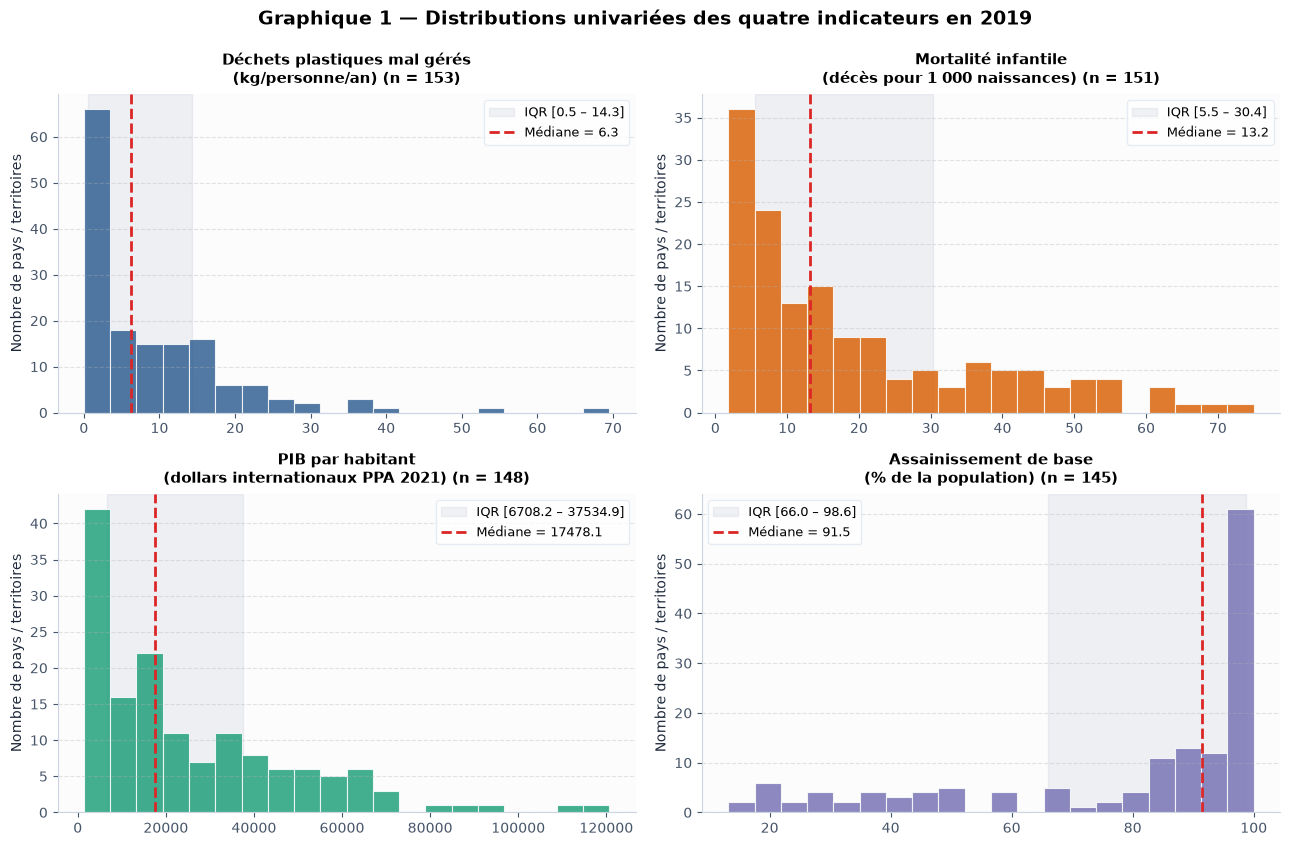

In [5]:
variables_hist = [
    ("plastic_kg_per_person", "Déchets plastiques mal gérés\n(kg/personne/an)", "#2b5c8f"),
    ("infant_mortality_per_1000", "Mortalité infantile\n(décès pour 1 000 naissances)", "#d95f02"),
    ("gdp_pc_ppp_2019", "PIB par habitant\n(dollars internationaux PPA 2021)", "#1b9e77"),
    ("basic_sanitation_pct", "Assainissement de base\n(% de la population)", "#7570b3"),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
axes = axes.flatten()

for ax, (col, titre, couleur) in zip(axes, variables_hist):
    valeurs = df_merged[col].dropna()
    med = valeurs.median()
    q1, q3 = valeurs.quantile(0.25), valeurs.quantile(0.75)

    ax.axvspan(q1, q3, color="#94a3b8", alpha=0.14, label=f"IQR [{q1:.1f} – {q3:.1f}]")
    ax.hist(valeurs, bins=20, color=couleur, alpha=0.82, edgecolor="white", linewidth=0.8)
    ax.axvline(med, color="#dc2626", linestyle="--", linewidth=2.0, label=f"Médiane = {med:.1f}")

    ax.set_title(f"{titre} (n = {len(valeurs)})", fontsize=11, pad=8)
    ax.set_ylabel("Nombre de pays / territoires")
    ax.legend(frameon=True, facecolor="white", edgecolor="#e2e8f0", fontsize=9)
    ax.grid(True, axis="y", linestyle="--", alpha=0.35)

fig.suptitle("Graphique 1 — Distributions univariées des quatre indicateurs en 2019", fontsize=14, fontweight="bold", y=0.99)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig1_distributions_2019.png", dpi=150, bbox_inches="tight")
plt.show()

<div style="background-color: #f8fafc; border: 1px solid #cbd5e1; border-left: 4px solid #1b9e77; padding: 14px 18px; border-radius: 6px; margin-top: 8px;">
  <div style="font-weight: 700; color: #0f5132; font-size: 14px; margin-bottom: 4px;">Enseignements du Graphique 1</div>
  <ul style="margin: 0; padding-left: 18px; color: #1e293b; font-size: 13.5px; line-height: 1.55;">
    <li><strong>Forte asymétrie à droite (queue étirée vers les valeurs hautes)</strong> pour les déchets plastiques mal gérés, la mortalité infantile et le PIB par habitant : la majorité des pays sont regroupés près des valeurs basses, tandis qu'une minorité présente des niveaux très élevés.</li>
    <li><strong>Asymétrie inverse (à gauche) pour l'assainissement de base :</strong> un grand nombre de pays se concentrent entre 90 % et 100 %, avec une traîne vers les faibles taux de couverture (13 % à 60 %).</li>
    <li><strong>Conséquence méthodologique :</strong> ces asymétries justifient l'emploi d'une <strong>échelle logarithmique</strong> et du <strong>coefficient de Spearman</strong> dans la section suivante.</li>
  </ul>
</div>

<a id="sec-6"></a>
## 6. Analyse bivariée : déchets plastiques et mortalité infantile (Graphique 2)

Nous examinons l’association descriptive entre les déchets plastiques mal gérés par habitant et la mortalité infantile parmi les pays/territoires pour lesquels ces deux valeurs sont disponibles (`df_pair`). Pearson résume l’alignement linéaire des valeurs; Spearman résume l’association entre leurs rangs. Ces coefficients ne démontrent pas de causalité.

Nous calculons aussi Spearman sur `df_complete`, qui ne garde que les pays/territoires avec les quatre indicateurs. Cette comparaison permet de voir si la restriction aux cas complets change beaucoup le résumé de la relation principale. Elle ne corrige pas un éventuel biais dû aux données manquantes.


Effectif étudié                : n = 151 pays/territoires
Corrélation de Pearson (r)     : 0.337
Corrélation de Spearman (rho)  : 0.585
Spearman sur les cas complets   : 0.608 (n = 139)


,Echantillon,n,Spearman
0,Déchets + mortalité,151,0.585
1,Quatre variables complètes,139,0.608


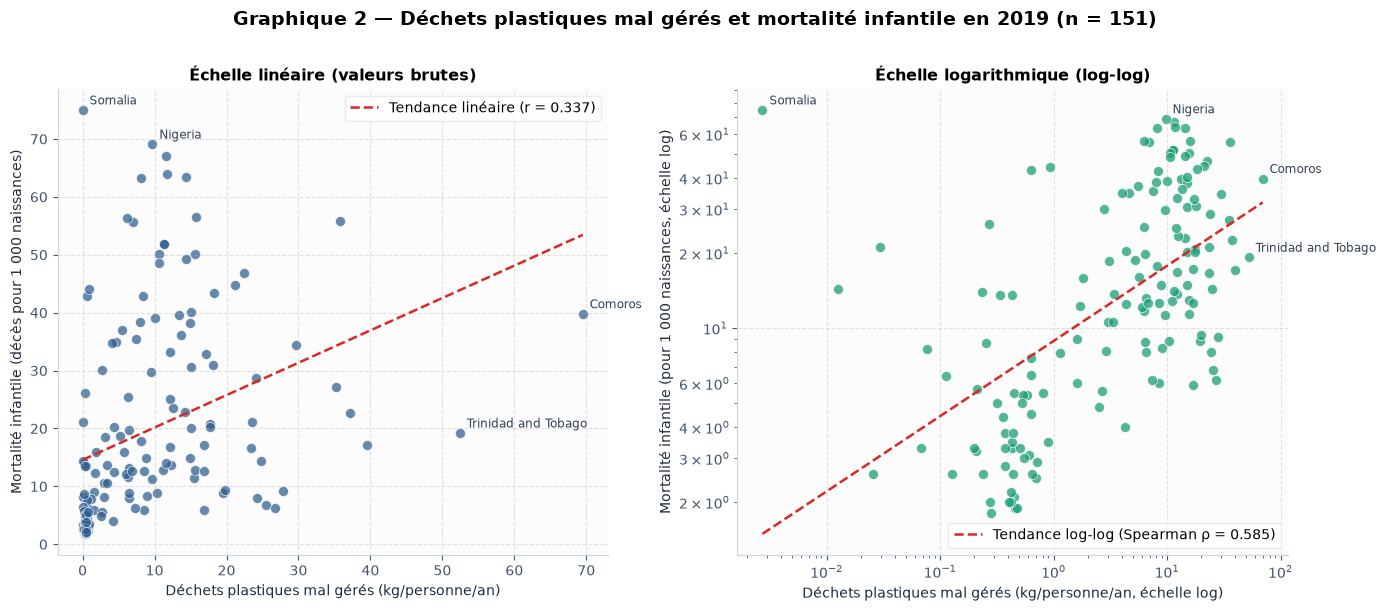

In [6]:
x_col = "plastic_kg_per_person"
y_col = "infant_mortality_per_1000"
name_col = next((c for c in ["entity", "country_name", "country", "name"] if c in df_pair.columns), "iso3")

# Calcul des corrélations sur l'échantillon principal (n = 151)
r_pearson = df_pair[x_col].corr(df_pair[y_col], method="pearson")
rho_spearman = df_pair[x_col].corr(df_pair[y_col], method="spearman")
rho_complete = df_complete[x_col].corr(df_complete[y_col], method="spearman")

print(f"Effectif étudié                : n = {len(df_pair)} pays/territoires")
print(f"Corrélation de Pearson (r)     : {r_pearson:.3f}")
print(f"Corrélation de Spearman (rho)  : {rho_spearman:.3f}")
print(f"Spearman sur les cas complets   : {rho_complete:.3f} (n = {len(df_complete)})")

sensitivity_df = pd.DataFrame([
    {"Echantillon": "Déchets + mortalité", "n": len(df_pair), "Spearman": rho_spearman},
    {"Echantillon": "Quatre variables complètes", "n": len(df_complete), "Spearman": rho_complete},
])
display(sensitivity_df.round(3))
sensitivity_df.to_csv(TABLES_DIR / "sensibilite_echantillon_2019.csv", index=False)

# Préparation des données strictement positives pour la représentation log-log
df_log = df_pair[(df_pair[x_col] > 0) & (df_pair[y_col] > 0)].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Panneau gauche : Échelle linéaire
ax1 = axes[0]
ax1.scatter(df_pair[x_col], df_pair[y_col], color="#2b5c8f", alpha=0.72, edgecolor="white", linewidth=0.6, s=52)
slope_lin, intercept_lin = np.polyfit(df_pair[x_col], df_pair[y_col], 1)
x_grid_lin = np.linspace(df_pair[x_col].min(), df_pair[x_col].max(), 100)
ax1.plot(x_grid_lin, slope_lin * x_grid_lin + intercept_lin, color="#dc2626", linestyle="--", linewidth=1.8,
         label=f"Tendance linéaire (r = {r_pearson:.3f})")
ax1.set_title("Échelle linéaire (valeurs brutes)", fontsize=11.5)
ax1.set_xlabel("Déchets plastiques mal gérés (kg/personne/an)")
ax1.set_ylabel("Mortalité infantile (décès pour 1 000 naissances)")
ax1.legend(frameon=True, facecolor="white", edgecolor="#e2e8f0")
ax1.grid(True, linestyle="--", alpha=0.35)

# Panneau droit : Échelle logarithmique (log-log)
ax2 = axes[1]
ax2.scatter(df_log[x_col], df_log[y_col], color="#1b9e77", alpha=0.75, edgecolor="white", linewidth=0.6, s=52)
slope_log, intercept_log = np.polyfit(np.log10(df_log[x_col]), np.log10(df_log[y_col]), 1)
x_grid_log = np.logspace(np.log10(df_log[x_col].min()), np.log10(df_log[x_col].max()), 100)
ax2.plot(x_grid_log, 10 ** (intercept_log + slope_log * np.log10(x_grid_log)), color="#dc2626", linestyle="--", linewidth=1.8,
         label=f"Tendance log-log (Spearman ρ = {rho_spearman:.3f})")
ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.set_title("Échelle logarithmique (log-log)", fontsize=11.5)
ax2.set_xlabel("Déchets plastiques mal gérés (kg/personne/an, échelle log)")
ax2.set_ylabel("Mortalité infantile (pour 1 000 naissances, échelle log)")
ax2.legend(frameon=True, facecolor="white", edgecolor="#e2e8f0")
ax2.grid(True, which="major", linestyle="--", alpha=0.35)

# Annotation de quelques pays remarquables (extrêmes sur chaque axe)
highlights = pd.concat([
    df_pair.nlargest(2, x_col),
    df_pair.nlargest(2, y_col),
    df_pair.nsmallest(1, x_col),
]).drop_duplicates(subset=["iso3"])

for _, row in highlights.iterrows():
    ax1.annotate(row[name_col], (row[x_col], row[y_col]), xytext=(5, 4), textcoords="offset points", fontsize=8.5, color="#334155")
    if row[x_col] > 0 and row[y_col] > 0:
        ax2.annotate(row[name_col], (row[x_col], row[y_col]), xytext=(5, 4), textcoords="offset points", fontsize=8.5, color="#334155")

fig.suptitle(f"Graphique 2 — Déchets plastiques mal gérés et mortalité infantile en 2019 (n = {len(df_pair)})", fontsize=13.5, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig2_plastique_vs_mortalite_2019.png", dpi=150, bbox_inches="tight")
plt.show()


<div style="background-color: #f8fafc; border: 1px solid #cbd5e1; border-left: 4px solid #1b9e77; padding: 14px 18px; border-radius: 6px; margin-top: 8px;">
  <div style="font-weight: 700; color: #0f5132; font-size: 14px; margin-bottom: 4px;">Interprétation du Graphique 2</div>
  <ul style="margin: 0; padding-left: 18px; color: #1e293b; font-size: 13.5px; line-height: 1.55;">
    <li><strong>Une association positive modérée à marquée :</strong> à l'échelle mondiale, les pays générant davantage de déchets plastiques mal gérés par habitant présentent tendanciellement une mortalité infantile plus élevée ($\rho = 0{,}585$ ; $r = 0{,}337$).</li>
    <li><strong>Pourquoi Spearman ($0{,}585$) dépasse nettement Pearson ($0{,}337$) :</strong> sur l'échelle linéaire (à gauche), les points sont fortement tassés près de l'origine tandis que quelques pays à très fort volume de déchets (comme les Comores ou Trinité-et-Tobago) écrasent la droite de régression. L'échelle logarithmique (à droite) dévoile une progression beaucoup plus régulière sur l'ensemble du spectre des pays.</li>
    <li><strong>Question suivante :</strong> cette corrélation globale reflète-t-elle un lien propre aux déchets plastiques, ou s'explique-t-elle par le fait que les pays à faible revenu et à faibles infrastructures sanitaires cumulent à la fois une mauvaise gestion des déchets et une mortalité infantile élevée ?</li>
  </ul>
</div>

<a id="sec-7"></a>
## 7. Analyse stratifiée selon le niveau de richesse — PIB par habitant (Graphique 3)

Pour répondre au deuxième volet de la problématique, nous travaillons sur l'échantillon des **$n = 139$ cas complets** (`df_complete`) et découpons les pays en **trois groupes équilibrés (terciles)** selon leur PIB par habitant en parité de pouvoir d'achat (PPA 2021) :
- **Groupe 1 (Tercile inférieur) :** pays à faible PIB par habitant.
- **Groupe 2 (Tercile médian) :** pays à PIB par habitant intermédiaire.
- **Groupe 3 (Tercile supérieur) :** pays à PIB par habitant élevé.

Si l'association observée au niveau mondial était uniquement due aux écarts de richesse entre pays pauvres et pays riches, les corrélations calculées **à l'intérieur de chaque groupe** devraient devenir beaucoup plus faibles ou disparaître.

,Groupe de PIB par habitant,n,Médiane plastique (kg/hab.),Médiane mortalité (‰),Pearson (r),Spearman (rho)
0,"T1 : PIB faible (< 9,713 $ PPA)",46,10.976,39.00,0.086,0.200
1,"T2 : PIB intermédiaire (9,713 – 31,301 $)",46,8.466,12.75,0.170,0.306
2,"T3 : PIB élevé (> 31,301 $ PPA)",47,0.474,3.50,0.629,0.416


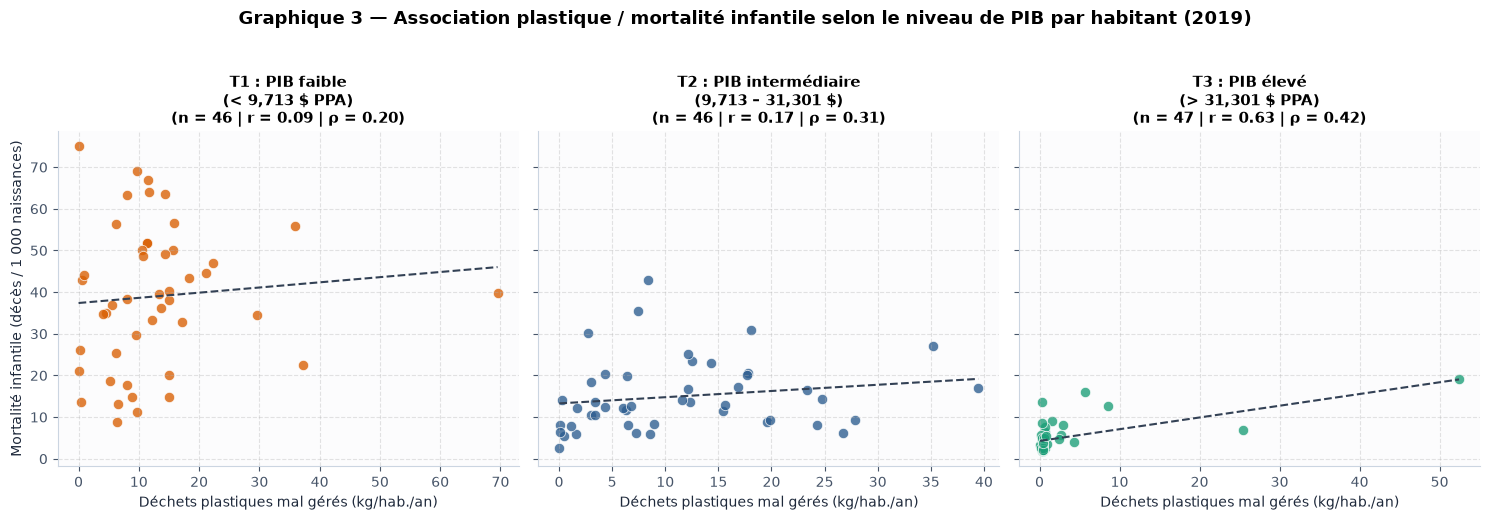

In [7]:
df_pib = df_complete.copy()
q33_pib, q66_pib = df_pib["gdp_pc_ppp_2019"].quantile([1/3, 2/3])

labels_pib = [
    f"T1 : PIB faible\n(< {q33_pib:,.0f} $ PPA)",
    f"T2 : PIB intermédiaire\n({q33_pib:,.0f} – {q66_pib:,.0f} $)",
    f"T3 : PIB élevé\n(> {q66_pib:,.0f} $ PPA)",
]
df_pib["groupe_pib"] = pd.qcut(df_pib["gdp_pc_ppp_2019"], q=3, labels=labels_pib)

# Tableau récapitulatif par groupe de PIB
rows_pib = []
for grp in labels_pib:
    sub = df_pib[df_pib["groupe_pib"] == grp]
    rows_pib.append({
        "Groupe de PIB par habitant": grp.replace("\n", " "),
        "n": len(sub),
        "Médiane plastique (kg/hab.)": sub[x_col].median(),
        "Médiane mortalité (‰)": sub[y_col].median(),
        "Pearson (r)": sub[x_col].corr(sub[y_col], method="pearson"),
        "Spearman (rho)": sub[x_col].corr(sub[y_col], method="spearman"),
    })

df_res_pib = pd.DataFrame(rows_pib)
display(df_res_pib.round(3))
df_res_pib.to_csv(TABLES_DIR / "correlations_par_groupe_pib.csv", index=False)

# Graphique 3 : Petits multiples par tercile de PIB
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
colors_pib = ["#d95f02", "#2b5c8f", "#1b9e77"]

for ax, grp, col_pt in zip(axes, labels_pib, colors_pib):
    sub = df_pib[df_pib["groupe_pib"] == grp]
    r_g = sub[x_col].corr(sub[y_col], method="pearson")
    rho_g = sub[x_col].corr(sub[y_col], method="spearman")

    ax.scatter(sub[x_col], sub[y_col], color=col_pt, alpha=0.78, edgecolor="white", linewidth=0.6, s=55)
    if len(sub) >= 3 and sub[x_col].nunique() > 1:
        m, b = np.polyfit(sub[x_col], sub[y_col], 1)
        xg = np.linspace(sub[x_col].min(), sub[x_col].max(), 50)
        ax.plot(xg, m * xg + b, color="#334155", linestyle="--", linewidth=1.5)

    ax.set_title(f"{grp}\n(n = {len(sub)} | r = {r_g:.2f} | ρ = {rho_g:.2f})", fontsize=10.5)
    ax.set_xlabel("Déchets plastiques mal gérés (kg/hab./an)")
    ax.grid(True, linestyle="--", alpha=0.35)

axes[0].set_ylabel("Mortalité infantile (décès / 1 000 naissances)")
fig.suptitle("Graphique 3 — Association plastique / mortalité infantile selon le niveau de PIB par habitant (2019)", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig3_stratification_pib_2019.png", dpi=150, bbox_inches="tight")
plt.show()

<div style="background-color: #f8fafc; border: 1px solid #cbd5e1; border-left: 4px solid #1b9e77; padding: 14px 18px; border-radius: 6px; margin-top: 8px;">
  <div style="font-weight: 700; color: #0f5132; font-size: 14px; margin-bottom: 4px;">Lecture descriptive des groupes de PIB</div>
  <ul style="margin: 0; padding-left: 18px; color: #1e293b; font-size: 13.5px; line-height: 1.55;">
    <li>La mortalité médiane est nettement plus élevée dans les groupes à PIB faible; les déchets mal gérés par habitant présentent aussi des niveaux différents entre groupes.</li>
    <li>Les corrélations de Spearman restent positives mais varient selon le tercile. Cette hétérogénéité décrit les données; elle ne montre pas que le PIB explique causalement la relation.</li>
    <li>Ces groupes ne sont pas une expérience et ne contrôlent pas les autres différences entre pays.</li>
  </ul>
</div>


<a id="sec-8"></a>
## 8. Analyse stratifiée selon les infrastructures — Accès à l'assainissement de base (Graphique 4)

Nous reproduisons la même démarche sur les **$n = 139$ cas complets** en classant les pays selon leur taux d'accès à un service d'assainissement de base (`basic_sanitation_pct`). Comme cet indicateur est fortement concentré au-dessus de 90 %, nous retenons **trois paliers sanitaires lisibles** :
- **Accès limité ($< 70\,\%$) :** pays où plus de 30 % de la population est dépourvue d'assainissement de base.
- **Accès intermédiaire ($70\,\%$ à $95\,\%$) :** pays en phase de généralisation des réseaux sanitaires.
- **Accès quasi universel ($\ge 95\,\%$) :** pays dotés d'infrastructures sanitaires couvrant la quasi-totalité de la population.

,Niveau d'accès à l'assainissement,n,Médiane plastique (kg/hab.),Médiane mortalité (‰),Pearson (r),Spearman (rho)
0,Accès limité (< 70 % de la pop.),40,11.464,42.85,-0.015,0.055
1,Accès intermédiaire (70 % – 95 %),41,7.291,13.70,0.361,0.452
2,Accès quasi universel (≥ 95 % de la pop.),58,0.565,5.20,0.423,0.520


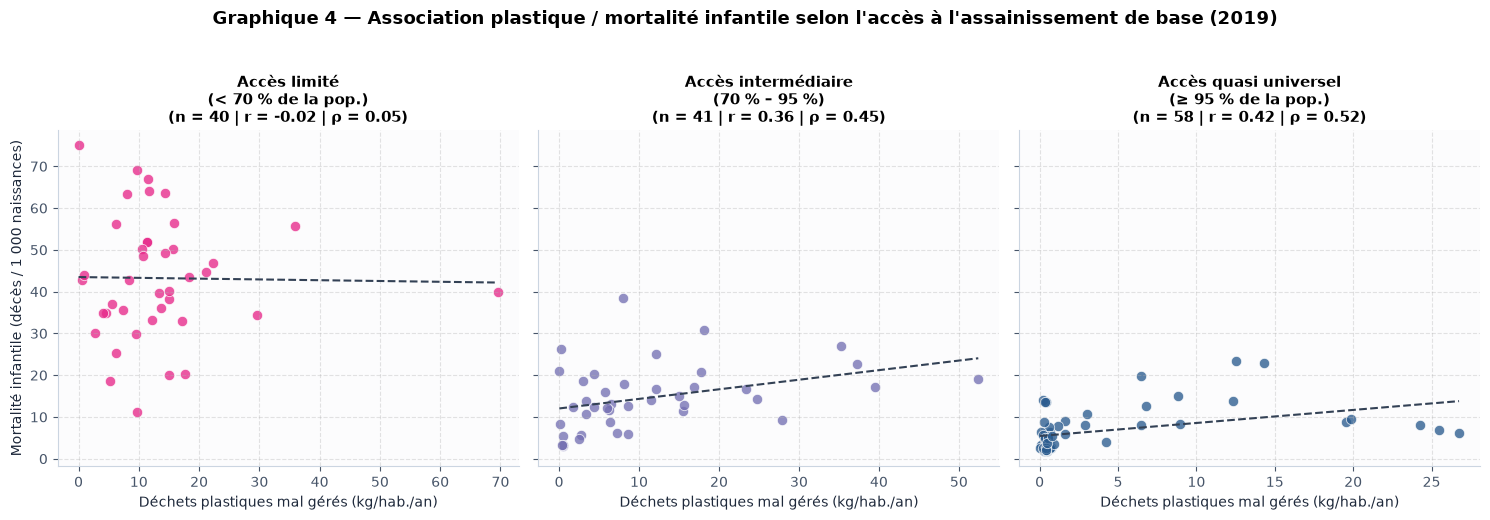

In [8]:
df_san = df_complete.copy()
bins_san = [0, 70, 95, 100.1]
labels_san = [
    "Accès limité\n(< 70 % de la pop.)",
    "Accès intermédiaire\n(70 % – 95 %)",
    "Accès quasi universel\n(≥ 95 % de la pop.)",
]
df_san["groupe_sanitation"] = pd.cut(df_san["basic_sanitation_pct"], bins=bins_san, labels=labels_san, right=False)

# Tableau récapitulatif par groupe d'assainissement
rows_san = []
for grp in labels_san:
    sub = df_san[df_san["groupe_sanitation"] == grp]
    rows_san.append({
        "Niveau d'accès à l'assainissement": grp.replace("\n", " "),
        "n": len(sub),
        "Médiane plastique (kg/hab.)": sub[x_col].median(),
        "Médiane mortalité (‰)": sub[y_col].median(),
        "Pearson (r)": sub[x_col].corr(sub[y_col], method="pearson"),
        "Spearman (rho)": sub[x_col].corr(sub[y_col], method="spearman"),
    })

df_res_san = pd.DataFrame(rows_san)
display(df_res_san.round(3))
df_res_san.to_csv(TABLES_DIR / "correlations_par_groupe_assainissement.csv", index=False)

# Graphique 4 : Petits multiples par niveau d'assainissement
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
colors_san = ["#e7298a", "#7570b3", "#2b5c8f"]

for ax, grp, col_pt in zip(axes, labels_san, colors_san):
    sub = df_san[df_san["groupe_sanitation"] == grp]
    r_g = sub[x_col].corr(sub[y_col], method="pearson")
    rho_g = sub[x_col].corr(sub[y_col], method="spearman")

    ax.scatter(sub[x_col], sub[y_col], color=col_pt, alpha=0.78, edgecolor="white", linewidth=0.6, s=55)
    if len(sub) >= 3 and sub[x_col].nunique() > 1:
        m, b = np.polyfit(sub[x_col], sub[y_col], 1)
        xg = np.linspace(sub[x_col].min(), sub[x_col].max(), 50)
        ax.plot(xg, m * xg + b, color="#334155", linestyle="--", linewidth=1.5)

    ax.set_title(f"{grp}\n(n = {len(sub)} | r = {r_g:.2f} | ρ = {rho_g:.2f})", fontsize=10.5)
    ax.set_xlabel("Déchets plastiques mal gérés (kg/hab./an)")
    ax.grid(True, linestyle="--", alpha=0.35)

axes[0].set_ylabel("Mortalité infantile (décès / 1 000 naissances)")
fig.suptitle("Graphique 4 — Association plastique / mortalité infantile selon l'accès à l'assainissement de base (2019)", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig4_stratification_assainissement_2019.png", dpi=150, bbox_inches="tight")
plt.show()

<div style="background-color: #f8fafc; border: 1px solid #cbd5e1; border-left: 4px solid #1b9e77; padding: 14px 18px; border-radius: 6px; margin-top: 8px;">
  <div style="font-weight: 700; color: #0f5132; font-size: 14px; margin-bottom: 4px;">Lecture descriptive des groupes d’assainissement</div>
  <ul style="margin: 0; padding-left: 18px; color: #1e293b; font-size: 13.5px; line-height: 1.55;">
    <li>Les médianes de mortalité diffèrent entre les trois niveaux d’accès à l’assainissement.</li>
    <li>Les corrélations de Spearman ne sont pas identiques entre groupes : l’association est particulièrement faible dans le groupe d’accès limité et plus forte dans les deux autres groupes.</li>
    <li>L’assainissement décrit ici l’accès aux installations sanitaires, pas la collecte des plastiques; ces comparaisons ne permettent pas d’isoler un effet causal.</li>
  </ul>
</div>


<a id="sec-9"></a>
## 9. Synthèse, limites et conclusion

<div style="background: linear-gradient(135deg, #16324f 0%, #2b5c8f 100%); color: #ffffff; padding: 20px 24px; border-radius: 10px; margin: 16px 0; box-shadow: 0 4px 12px rgba(0,0,0,0.08);">
  <div style="font-size: 12px; text-transform: uppercase; letter-spacing: 1.2px; opacity: 0.85; margin-bottom: 5px;">Bilan de l’analyse descriptive</div>
  <div style="font-size: 20px; font-weight: 700; margin-bottom: 12px;">Conclusion</div>
  <p style="margin: 0 0 10px 0; line-height: 1.6;">
    Dans le snapshot de 2019, parmi les <strong>151 pays et territoires</strong> disposant des deux indicateurs principaux, Spearman est d’environ <strong>0,585</strong> et Pearson d’environ <strong>0,337</strong>. Les rangs des déchets plastiques mal gérés par habitant et de la mortalité infantile tendent donc à varier dans le même sens à l’échelle nationale.
  </p>
  <p style="margin: 0; line-height: 1.6;">
    Le notebook compare aussi le résultat sur les <strong>139 cas complets</strong> et décrit les associations au sein des groupes de PIB et d’assainissement. Leur force varie selon les groupes : les résultats ne permettent pas d’attribuer les différences observées à un effet propre du plastique.
  </p>
</div>

<div style="background-color: #fffbeb; border-left: 5px solid #d97706; padding: 18px 22px; border-radius: 8px; margin: 16px 0;">
  <div style="font-weight: 700; color: #92400e; font-size: 16px; margin-bottom: 8px;">Limites et prudence d’interprétation</div>
  <ul style="margin: 0; padding-left: 20px; color: #78350f; line-height: 1.65;">
    <li>Il s’agit d’une coupe transversale pour 2019, et non d’une analyse de l’évolution dans le temps.</li>
    <li>L’unité d’analyse est le pays ou le territoire : une association nationale ne permet pas de conclure au risque d’un enfant individuellement (risque d’erreur écologique).</li>
    <li>Les déchets plastiques mal gérés sont une estimation par habitant; ils ne mesurent pas l’exposition individuelle ni la pollution au domicile.</li>
    <li>L’indicateur d’assainissement décrit l’accès à des installations sanitaires, pas la collecte ou le traitement des déchets plastiques.</li>
    <li>Des données manquent pour certaines entités et d’autres facteurs sanitaires, économiques ou contextuels ne sont pas étudiés.</li>
    <li>Les statistiques descriptives et les corrélations ne démontrent pas de causalité.</li>
  </ul>
</div>

<p style="color: #475569; font-size: 13px;">
  Les résultats dépendent des fichiers locaux dans <code>data/raw/</code>. Les sources pouvant être mises à jour, toute nouvelle extraction doit être suivie d’une nouvelle exécution du notebook et d’une vérification des chiffres.
</p>